# SupCon learning

## build datasets

/home/hmack/Development/smartrodent_experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'len(dataset)=7173'

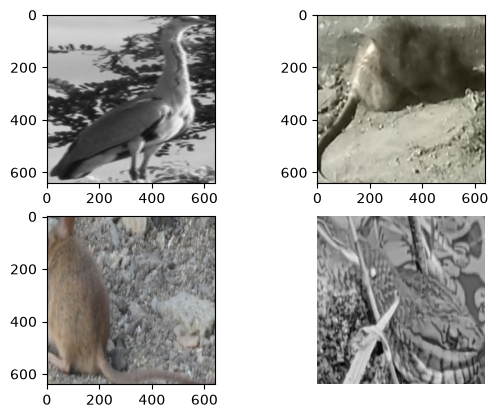

In [1]:
from smartrodent.supcon_datasets import ImageDataset, MultiViewImageDataset

from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if not (project_root / "pyproject.toml").exists():
    raise RuntimeError("Run this notebook from the repository root or notebooks directory")

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from pytorch_metric_learning.samplers import MPerClassSampler
from torchvision.transforms.v2 import (
    Compose,
    InterpolationMode,
    PILToTensor,
    RandomAdjustSharpness,
    RandomGrayscale,
    RandomHorizontalFlip,
    RandomPerspective,
    RandomResizedCrop,
    Resize,
    ToDtype,
)

# params
size = 640
labels = sorted(
    [
        "Ardea cinerea",
        "Bandicota indica",
        "Coelognathus helena",
        "Mus musculus",
        "Bandicota bengalensis",
        "Rattus rattus",
        "Rattus norvegicus",
        "Suncus murinus",
        "Sorex araneus",
        "Natrix natrix",
    ]
)
path = Path(
    project_root / "datasets/stage8_yolo_classifier_not_oversampled/train"
)
seed = 42
p = 4  # number of classes
m = 3  # number of examples

transform = Compose(
    [
        PILToTensor(),
        ToDtype(torch.float32, scale=True),
        Resize((size, size), antialias=True),
        RandomAdjustSharpness(sharpness_factor=0.7, p=0.2),
        RandomGrayscale(p=0.2),
        RandomPerspective(
            distortion_scale=0.2,
            p=0.2,
            interpolation=InterpolationMode.BILINEAR,
            fill=0,
        ),
        RandomHorizontalFlip(
            p=0.2,
        ),
        RandomResizedCrop(
            (size, size),
            scale=(0.7, 1.0),
            ratio=(3.0 / 4.0, 4.0 / 3.0),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
    ]
)
dataset = ImageDataset(path, transform=transform, labels=labels, size=size)

# set numpy seed
np.random.seed(seed)

# make dataset
# check that images are loaded and augmented
display(f"len(dataset)={len(dataset)}")
fig, subplots = plt.subplots(2, 2)
lbl1, img1 = dataset[1002]
img1 = img1.detach().cpu().permute(1, 2, 0).numpy()

lbl2, img2 = dataset[2002]
img2 = img2.detach().cpu().permute(1, 2, 0).numpy()

lbl3, img3 = dataset[3002]
img3 = img3.detach().cpu().permute(1, 2, 0).numpy()

lbl4, img4 = dataset[4002]
img4 = img4.detach().cpu().permute(1, 2, 0).numpy()

subplots[0, 0].imshow(img1, label=lbl1)
subplots[0, 1].imshow(img2, label=lbl2)
subplots[1, 0].imshow(img3, label=lbl3)
subplots[1, 1].imshow(img4, label=lbl4)

plt.axis("off")
plt.show()


/tmp/ipykernel_114550/230741161.py:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


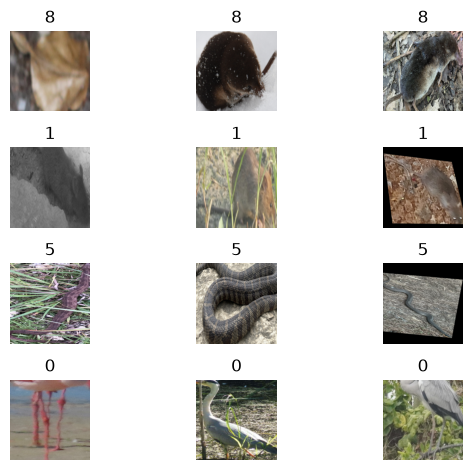

In [2]:
from collections.abc import Iterable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.transforms.v2 import (
    Compose,
    InterpolationMode,
    PILToTensor,
    RandomAdjustSharpness,
    RandomGrayscale,
    RandomHorizontalFlip,
    RandomPerspective,
    RandomResizedCrop,
    Resize,
)

# make sampler and dataloader
sample_labels = [dataset.label_names[path.parent.name] for path in dataset.images]
sampler = MPerClassSampler(labels=sample_labels, m=m, batch_size=p * m)
transform = Compose(
    [
        PILToTensor(),
        ToDtype(torch.float32, scale=True),
        Resize((size, size), antialias=True),
        RandomAdjustSharpness(sharpness_factor=0.5, p=0.2),
        RandomGrayscale(p=0.2),
        RandomPerspective(
            distortion_scale=0.4,
            p=0.2,
            interpolation=InterpolationMode.BILINEAR,
            fill=0,
        ),
        RandomHorizontalFlip(
            p=0.2,
        ),
        RandomResizedCrop(
            (size, size),
            scale=(0.75, 1.0),
            ratio=(3.0 / 4.0, 4.0 / 3.0),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
    ]
)
dataset = ImageDataset(path, transform=transform, labels=labels, size=size)

rng = torch.random.manual_seed(seed)
# Defining a custom data loader
dataloader = torch.utils.data.DataLoader(
    # Replace with the dataset object
    dataset=dataset,
    # Defining the batch size
    batch_size=p * m,
    # If true, shuffles the dataset at every epoch. Cannot be used with explicit sampler
    shuffle=False,
    # sampler to build the main issues.
    sampler=sampler,
    # Number of parallel processes for loading the data
    num_workers=0,
    # generator
    generator=rng,
    # multiprocessing context
    # multiprocessing_context="spawn"
    drop_last=True,
)

labelsstr, images = next(iter(dataloader))
fig, subplots = plt.subplots(p, m)
for lbl, img, ax in zip(labelsstr, images, subplots.flatten()):
    img = img.detach().cpu().permute(1, 2, 0).numpy()
    ax.imshow(img, label=lbl)
    ax.set_title(int(lbl))
    ax.axis("off")
fig.tight_layout()
fig.show()


## Model from ultralytics 

We need pooled, projected embeddings. loss is supplied by pytorch-metric learning

## Standalone training

Run from the repository root in the project environment:

```bash
python scripts/train_supcon.py configs/train_supcon_config.yaml
```

The configuration preserves the notebook's FP32, two-view experiment. Each epoch writes an architecture-and-weights checkpoint, optimizer state, class mapping, configuration, and scalar history under `runs/supcon_standalone_xl/`.

The training implementation is independent of the older Ultralytics trainer in `smartrodent.yolo_supcon`. Checkpoints and evaluation can be used in a fresh notebook session without repeating training.


In [3]:
# Saved output from the original notebook experiment.
# New training runs use scripts/train_supcon.py.


In [4]:
from smartrodent.supcon_model import YoloSupConModel

# Existing notebook experiment, preserved when moving training into the script.
# For a new script run, use runs/supcon_standalone_xl/epoch_0005.pt instead.
eval_trained_checkpoint = project_root / "runs/supcon_test_xl/epoch_0005.pt"
model = YoloSupConModel.from_checkpoint(eval_trained_checkpoint, device="cpu")
model.finalize()  # Evaluation uses its own temporary feature hook.

size = model.training_configuration["image_size"]
seed = model.training_configuration["seed"]
labels = sorted(model.label_names)
path = Path(model.training_configuration["train_dataset"])
if not path.is_absolute():
    path = project_root / path
dataset = ImageDataset(path, labels=labels)
print("Loaded checkpoint:", eval_trained_checkpoint)


YOLO26x-cls summary: 176 layers, 29,637,064 parameters, 29,637,064 gradients, 111.4 GFLOPs
Loaded checkpoint: /home/hmack/Development/smartrodent_experiments/runs/supcon_test_xl/epoch_0005.pt


## Eval

Compare the **same balanced subset of original images** through the pretrained encoder, trained encoder, and trained projector. Preprocessing is deterministic: RGB conversion, float scaling, and resizing, with no random augmentation.

Load the trained checkpoint in the cell above before running these cells. Extraction works after `model.finalize()` and temporarily disables dropout and BatchNorm updates, restoring their previous modes afterward. Feature arrays are copied to CPU.

The baseline checkpoint defaults to CPU so a second model is not allocated on the training GPU. The three t-SNE panels use separate fits and consistent species colors; their axes and inter-cluster positions are not a shared coordinate system. Labels are used for selection and coloring, not to fit t-SNE.


In [5]:
from collections import Counter
from smartrodent.eval import EvaluationImages, FeatureExtractor, TsneComparison
from ultralytics import YOLO

# Explicitly cap the balanced subset at the least-populated species.
eval_class_counts = Counter(image.parent.name for image in dataset.images)
eval_samples_per_class = min(
    100, min(eval_class_counts[name] for name in dataset.label_names)
)
eval_images = EvaluationImages(
    images=dataset.images,
    label_names=dataset.label_names,
    samples_per_class=eval_samples_per_class,
    image_size=size,
    seed=seed,
)
eval_batch_size = 8
eval_workers = 0
eval_checkpoint = Path(model.training_configuration["model_name"])
if not eval_checkpoint.is_absolute():
    eval_checkpoint = project_root / eval_checkpoint
eval_baseline_device = "cpu"  # Set to "cuda" if you prefer after training.
eval_perplexity = min(30.0, len(eval_images) - 1)
print(
    f"Eval: {eval_samples_per_class} images per species, "
    f"{len(eval_images)} total; perplexity={eval_perplexity}"
)


Eval: 15 images per species, 90 total; perplexity=30.0


In [6]:
# Baseline: load the original weights, using precisely the same source images.
eval_baseline = YOLO(eval_checkpoint, task="classify")
try:
    eval_baseline.model.to(eval_baseline_device)
    baseline_features = FeatureExtractor(
        network=eval_baseline.model,
        pool=eval_baseline.model.model[-1].pool,
    ).extract(eval_images, batch_size=eval_batch_size, num_workers=eval_workers)
finally:
    del eval_baseline

print("Pretrained pooled:", baseline_features.pooled.shape)


Pretrained pooled: (90, 1280)


In [7]:
# Use the trained weights already held in memory; do not reload the checkpoint.
trained_features = FeatureExtractor(
    network=model.full_model.model,
    pool=model.head.pool,
    projector=model.projector,
).extract(eval_images, batch_size=eval_batch_size, num_workers=eval_workers)

print("Trained pooled:", trained_features.pooled.shape)
print("Trained projected:", trained_features.projected.shape)


Trained pooled: (90, 1280)
Trained projected: (90, 128)


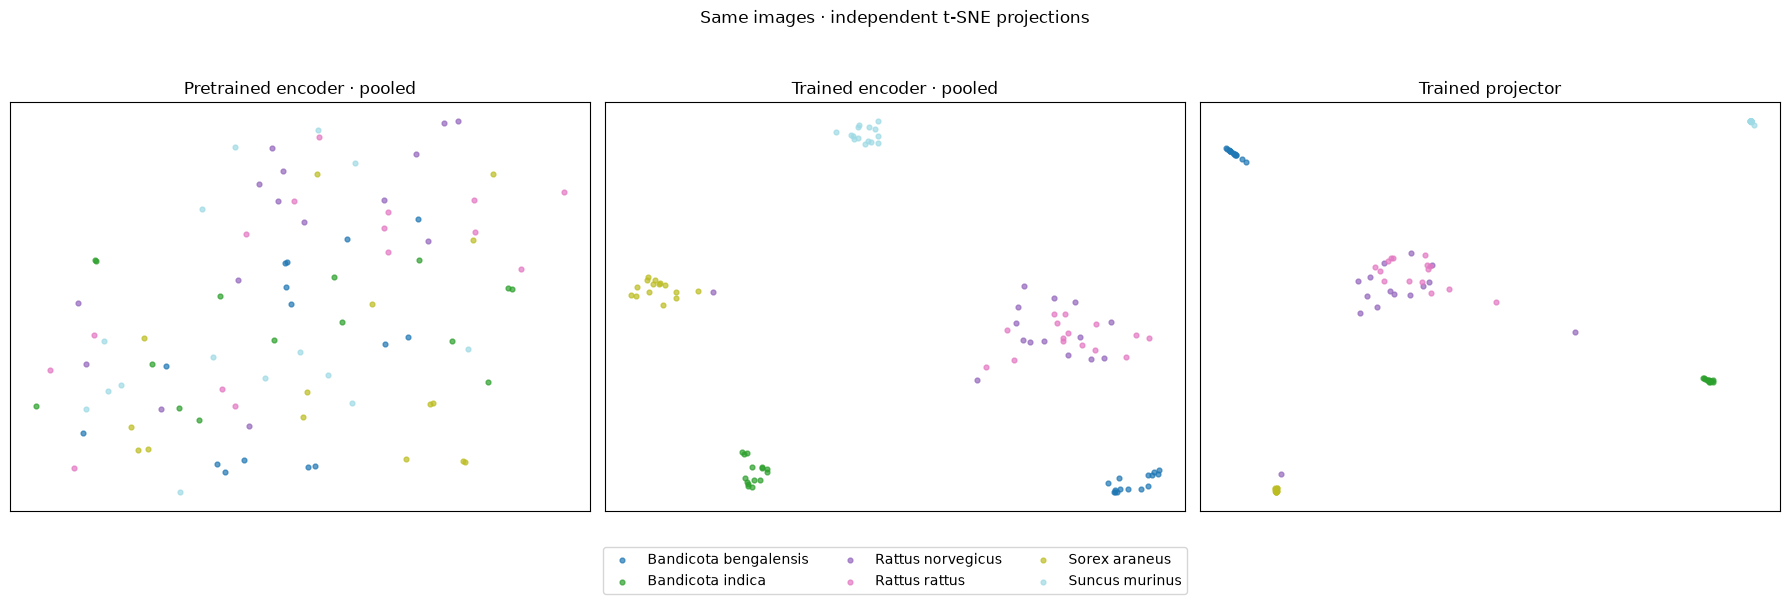

In [8]:
eval_comparison = TsneComparison(
    perplexity=eval_perplexity,
    pca_components=50,
    seed=seed,
    max_iter=1000,
)
eval_figure, eval_coordinates = eval_comparison.plot(
    baseline=baseline_features,
    trained=trained_features,
)
plt.show()

# Optional export, outside the image dataset:
# eval_figure.savefig("eval_embeddings.png", dpi=200, bbox_inches="tight")


### Experiment observation

The first t-SNE inspection showed substantial overlap between **Rattus rattus** and **Rattus norvegicus** with the current augmentations. The other included species appeared better separated. This is a visual observation from this experiment, not a held-out classification result; revisit it when comparing augmentation settings and the pooled versus projected representations.
